
# 07 — Evaluación comparativa de modelos

## Taller de Análisis de Datos I — TP3

### Objetivo

Comparar los resultados de los modelos de corrección
de pronósticos meteorológicos de temperatura para
horizontes de 12 y 24 horas.

### Modelos evaluados

- B0: Pronóstico original.
- B1: Corrección por sesgo global.
- B2: Corrección por horizonte.
- B3: Corrección por estación.
- Ridge con errores históricos.
- HistGradientBoosting con errores históricos.

### Fuentes de evaluación

Se presentan por separado:

1. Validación histórica del 18/10 al 01/11,
   excluyendo los días anómalos.
2. Validación cruzada temporal con cuatro folds.
3. Prueba final del 02/11 al 09/11.

### Criterios de comparación

- MAE: error absoluto medio.
- RMSE: raíz del error cuadrático medio.
- Sesgo: promedio del error firmado.
- Reducción porcentual del MAE frente al pronóstico original.
- Consistencia temporal de las mejoras.

### Consideraciones metodológicas

La validación cruzada es un análisis retrospectivo de
robustez con hiperparámetros previamente seleccionados.

La prueba final se realizó sin reajustar el modelo.

Las métricas de diferentes períodos se presentan
separadamente para evitar comparaciones inapropiadas.

Este notebook consolida resultados ya obtenidos.
No vuelve a entrenar modelos.


In [1]:

# ==========================================
# 07 - CELDA 1
# RECUPERACIÓN DE RESULTADOS COMPARATIVOS
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------
# 1. LOCALIZAR PROYECTO
# ------------------------------------------

raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

assert (raiz / "dataset").is_dir()

print("PROYECTO:")
print(raiz)

# ------------------------------------------
# 2. LOCALIZAR ARCHIVOS EXPORTADOS
# ------------------------------------------

archivos = {
    "baseline_horizontes": (
        raiz / "resultados_baselines"
        / "01_baselines_por_horizonte.csv"
    ),
    "baseline_global": (
        raiz / "resultados_baselines"
        / "02_baselines_globales.csv"
    ),
    "cv_folds": (
        raiz / "resultados_ml"
        / "validacion_cruzada"
        / "01_comparacion_por_fold.csv"
    ),
    "cv_global": (
        raiz / "resultados_ml"
        / "validacion_cruzada"
        / "02_comparacion_consolidada.csv"
    ),
    "validacion_historica": (
        raiz / "resultados_ml"
        / "interpretabilidad"
        / "07_resumen_sesgos.csv"
    ),
    "test_horizontes": (
        raiz / "resultados_ml"
        / "01_metricas_por_horizonte.csv"
    ),
    "test_global": (
        raiz / "resultados_ml"
        / "02_metricas_globales.csv"
    )
}

print("\nARCHIVOS VERIFICADOS:")

for nombre, ruta in archivos.items():
    print(
        nombre,
        "OK" if ruta.is_file() else "FALTANTE"
    )

faltantes = [
    str(ruta)
    for ruta in archivos.values()
    if not ruta.is_file()
]

assert not faltantes, (
    "Faltan archivos:\n"
    + "\n".join(faltantes)
)

# ------------------------------------------
# 3. LEER RESULTADOS
# ------------------------------------------

datos = {
    nombre: pd.read_csv(ruta)
    for nombre, ruta in archivos.items()
}

df_07_baselines = datos["baseline_global"]
df_07_cv = datos["cv_global"]
df_07_validacion = datos["validacion_historica"]
df_07_test = datos["test_global"]

# ------------------------------------------
# 4. MOSTRAR BASELINES
# ------------------------------------------

print("\n1. BASELINES - VALIDACIÓN HISTÓRICA")

display(
    df_07_baselines[
        [
            "modelo",
            "registros",
            "MAE_c",
            "RMSE_c",
            "sesgo_c",
            "mejora_MAE_pct"
        ]
    ].sort_values("MAE_c").round(4)
)

# ------------------------------------------
# 5. MOSTRAR VALIDACIÓN HISTÓRICA
# ------------------------------------------

print("\n2. RIDGE Y HGB - VALIDACIÓN HISTÓRICA")

display(
    df_07_validacion.round(4)
)

# ------------------------------------------
# 6. MOSTRAR VALIDACIÓN CRUZADA
# ------------------------------------------

print("\n3. VALIDACIÓN CRUZADA TEMPORAL")

columnas_cv = [
    "horizonte_h",
    "registros",
    "MAE_original_c",
    "MAE_ridge_c",
    "MAE_hgb_c",
    "mejora_ridge_pct",
    "mejora_hgb_pct"
]

display(
    df_07_cv[columnas_cv].round(4)
)

# ------------------------------------------
# 7. MOSTRAR PRUEBA FINAL
# ------------------------------------------

print("\n4. PRUEBA FINAL INDEPENDIENTE")

display(
    datos["test_horizontes"].round(4)
)

print("\nRESULTADO GLOBAL DE NOVIEMBRE:")

display(
    df_07_test.round(4)
)

# ------------------------------------------
# 8. COMPROBAR COHERENCIA
# ------------------------------------------

assert len(df_07_baselines) == 4
assert len(df_07_validacion) == 3
assert len(df_07_cv) == 3

assert (
    df_07_baselines["registros"] == 173583
).all()

assert (
    df_07_validacion.loc[
        df_07_validacion["horizonte_h"]
        .astype(str) == "Global",
        "registros"
    ].iloc[0] == 173583
)

assert (
    df_07_cv.loc[
        df_07_cv["horizonte_h"]
        .astype(str) == "Global",
        "registros"
    ].iloc[0] == 513506
)

assert df_07_test["registros"].iloc[0] == 140822

# Comparación de B0 entre dos notebooks
mae_baseline_original = (
    df_07_baselines.loc[
        df_07_baselines["modelo"]
        == "B0 - Original",
        "MAE_c"
    ].iloc[0]
)

mae_validacion_original = (
    df_07_validacion.loc[
        df_07_validacion["horizonte_h"]
        .astype(str) == "Global",
        "MAE_original_c"
    ].iloc[0]
)

assert np.isclose(
    mae_baseline_original,
    mae_validacion_original,
    atol=1e-6
)

print("\nCONTROL FINAL:")
print("Siete archivos de resultados recuperados.")
print("Baselines y validación histórica coherentes.")
print("Validación cruzada identificada por separado.")
print("Prueba final independiente identificada.")
print("Sin nuevos entrenamientos.")
print("Sin modificación de métricas.")


PROYECTO:
c:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3

ARCHIVOS VERIFICADOS:
baseline_horizontes OK
baseline_global OK
cv_folds OK
cv_global OK
validacion_historica OK
test_horizontes OK
test_global OK

1. BASELINES - VALIDACIÓN HISTÓRICA


,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
3,B3 - Sesgo por estación,173583,1.5297,1.9218,0.1544,2.1985
2,B2 - Sesgo por horizonte,173583,1.5625,1.9698,0.1277,0.1046
1,B1 - Sesgo global,173583,1.5625,1.9698,0.1277,0.1042
0,B0 - Original,173583,1.5641,1.9719,0.1570,0.0000



2. RIDGE Y HGB - VALIDACIÓN HISTÓRICA


,horizonte_h,registros,MAE_original_c,sesgo_original_c,MAE_ridge_c,sesgo_ridge_c,MAE_hgb_c,sesgo_hgb_c
0,12,86792,1.5636,0.1572,1.5044,-0.0256,1.4369,-0.0432
1,24,86791,1.5646,0.1568,1.4702,-0.0324,1.4353,-0.0359
2,Global,173583,1.5641,0.1570,1.4873,-0.0290,1.4361,-0.0396



3. VALIDACIÓN CRUZADA TEMPORAL


,horizonte_h,registros,MAE_original_c,MAE_ridge_c,MAE_hgb_c,mejora_ridge_pct,mejora_hgb_pct
0,12,256757,1.3870,1.4125,1.2589,-1.8351,9.2362
1,24,256749,1.4617,1.4606,1.3236,0.0782,9.4492
2,Global,513506,1.4244,1.4365,1.2912,-0.8534,9.3455



4. PRUEBA FINAL INDEPENDIENTE


,horizonte_h,registros,MAE_original_c,MAE_corregido_c,RMSE_original_c,RMSE_corregido_c,sesgo_original_c,sesgo_corregido_c,mejora_MAE_pct
0,12,70401,1.4620,1.3051,1.8458,1.6669,0.3144,0.1291,10.7273
1,24,70421,1.5194,1.3635,1.9136,1.7347,0.3628,0.1792,10.2572



RESULTADO GLOBAL DE NOVIEMBRE:


,registros,MAE_original_c,MAE_corregido_c,RMSE_original_c,RMSE_corregido_c,sesgo_original_c,sesgo_corregido_c,mejora_MAE_pct
0,140822,1.4907,1.3343,1.88,1.7012,0.3386,0.1541,10.4877



CONTROL FINAL:
Siete archivos de resultados recuperados.
Baselines y validación histórica coherentes.
Validación cruzada identificada por separado.
Prueba final independiente identificada.
Sin nuevos entrenamientos.
Sin modificación de métricas.


#### Qué haremos después
Una vez que esta celda confirme la coherencia de los resultados, construiremos la tabla comparativa final, con gráficos que distingan claramente:
- Los cuatro baselines frente a Ridge y HGB en validación histórica.
- La estabilidad de Ridge y HGB en validación cruzada.
- La mejora del modelo final sobre noviembre.

COMPARACIÓN HISTÓRICA DEFINITIVA:


,modelo,registros,MAE_c,mejora_MAE_pct,sesgo_c,sesgo_absoluto_c
0,HGB - Con lags,173583,1.4361,8.1845,-0.0396,0.0396
1,Ridge - Con lags,173583,1.4873,4.9099,-0.0290,0.0290
2,B3 - Sesgo por estación,173583,1.5297,2.1985,0.1544,0.1544
3,B2 - Sesgo por horizonte,173583,1.5625,0.1046,0.1277,0.1277
4,B1 - Sesgo global,173583,1.5625,0.1042,0.1277,0.1277
5,B0 - Original,173583,1.5641,0.0000,0.1570,0.1570


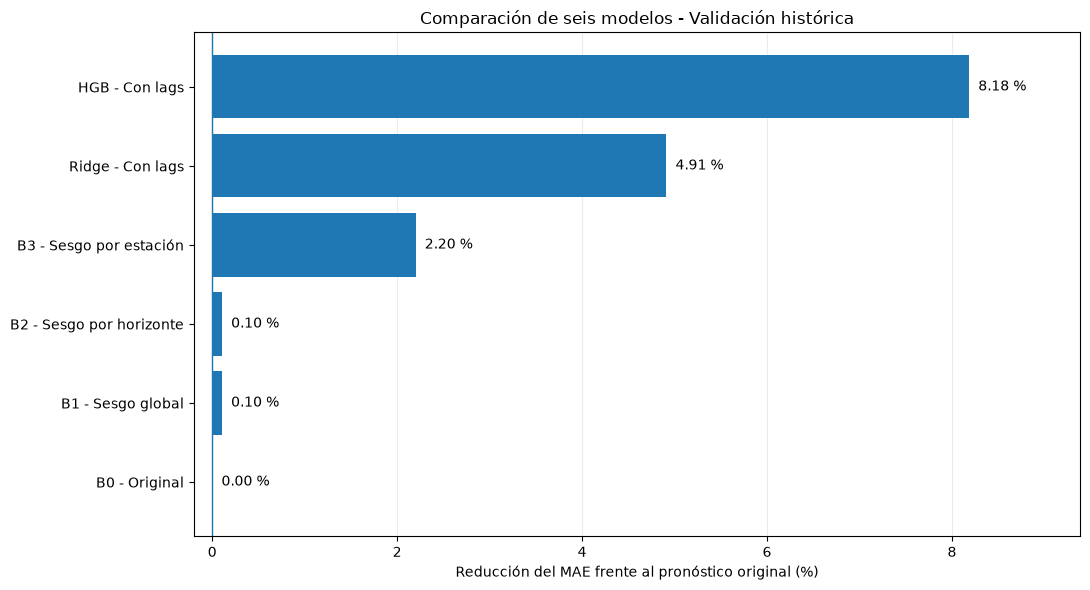


MEJOR MODELO:
HGB - Con lags
MAE: 1.4361 °C
Mejora: 8.1845 %

CONTROL FINAL:
Seis modelos comparados.
173583 registros de validación común.
Tabla y gráfico exportados.
Sin entrenamiento de modelos.
Sin modificación de resultados.
Prueba final de noviembre intacta.


In [2]:

# ==========================================
# 07 - CELDA 2
# COMPARACIÓN DE LOS SEIS MODELOS
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. RECUPERAR BASELINES
# ------------------------------------------

df_comparacion_07 = df_07_baselines[
    [
        "modelo",
        "registros",
        "MAE_c",
        "sesgo_c"
    ]
].copy()

# ------------------------------------------
# 2. RECUPERAR RIDGE Y HGB
# ------------------------------------------

validacion_global = df_07_validacion.loc[
    df_07_validacion["horizonte_h"]
    .astype(str).eq("Global")
]

assert len(validacion_global) == 1

fila = validacion_global.iloc[0]

modelos_ml = pd.DataFrame([
    {
        "modelo": "Ridge - Con lags",
        "registros": int(fila["registros"]),
        "MAE_c": float(fila["MAE_ridge_c"]),
        "sesgo_c": float(fila["sesgo_ridge_c"])
    },
    {
        "modelo": "HGB - Con lags",
        "registros": int(fila["registros"]),
        "MAE_c": float(fila["MAE_hgb_c"]),
        "sesgo_c": float(fila["sesgo_hgb_c"])
    }
])

df_comparacion_07 = pd.concat(
    [df_comparacion_07, modelos_ml],
    ignore_index=True
)

# ------------------------------------------
# 3. VALIDAR EL CONJUNTO COMÚN
# ------------------------------------------

assert len(df_comparacion_07) == 6
assert df_comparacion_07["modelo"].is_unique

assert (
    df_comparacion_07["registros"] == 173583
).all()

assert np.isfinite(
    df_comparacion_07[["MAE_c", "sesgo_c"]]
    .to_numpy(dtype=float)
).all()

original = df_comparacion_07.loc[
    df_comparacion_07["modelo"].eq("B0 - Original")
]

assert len(original) == 1

mae_original = float(
    original["MAE_c"].iloc[0]
)

sesgo_original = float(
    original["sesgo_c"].iloc[0]
)

assert np.isclose(
    mae_original,
    float(fila["MAE_original_c"]),
    atol=1e-6
)

assert np.isclose(
    sesgo_original,
    float(fila["sesgo_original_c"]),
    atol=1e-6
)

# ------------------------------------------
# 4. CALCULAR MEJORAS
# ------------------------------------------

df_comparacion_07["mejora_MAE_pct"] = (
    100 * (
        1 - df_comparacion_07["MAE_c"]
        / mae_original
    )
)

df_comparacion_07["sesgo_absoluto_c"] = (
    df_comparacion_07["sesgo_c"].abs()
)

df_comparacion_07 = (
    df_comparacion_07
    .sort_values("MAE_c")
    .reset_index(drop=True)
)

print("COMPARACIÓN HISTÓRICA DEFINITIVA:")

display(
    df_comparacion_07[
        [
            "modelo",
            "registros",
            "MAE_c",
            "mejora_MAE_pct",
            "sesgo_c",
            "sesgo_absoluto_c"
        ]
    ].round(4)
)

# ------------------------------------------
# 5. REPRESENTAR MEJORA DEL MAE
# ------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    df_comparacion_07["modelo"],
    df_comparacion_07["mejora_MAE_pct"]
)

ax.invert_yaxis()

ax.axvline(
    0,
    linewidth=1
)

ax.set_xlabel(
    "Reducción del MAE frente al pronóstico original (%)"
)

ax.set_title(
    "Comparación de seis modelos - Validación histórica"
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

valores = df_comparacion_07[
    "mejora_MAE_pct"
].to_numpy()

for barra, valor in zip(barras, valores):

    ax.text(
        valor + 0.10,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f} %",
        ha="left",
        va="center"
    )

ax.set_xlim(
    min(0, valores.min()) - 0.2,
    max(0, valores.max()) + 1.2
)

fig.tight_layout()

# ------------------------------------------
# 6. EXPORTAR RESULTADOS
# ------------------------------------------

carpeta_evaluacion = (
    raiz / "resultados_ml"
    / "evaluacion_comparativa"
)

carpeta_evaluacion.mkdir(
    parents=True,
    exist_ok=True
)

ruta_tabla = (
    carpeta_evaluacion
    / "01_comparacion_seis_modelos.csv"
)

ruta_grafico = (
    carpeta_evaluacion
    / "02_comparacion_seis_modelos.png"
)

df_comparacion_07.to_csv(
    ruta_tabla,
    index=False,
    encoding="utf-8-sig"
)

fig.savefig(
    ruta_grafico,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------
# 7. CONTROL FINAL
# ------------------------------------------

mejor_modelo = df_comparacion_07.iloc[0]

assert mejor_modelo["modelo"] == "HGB - Con lags"

assert ruta_tabla.is_file()
assert ruta_grafico.is_file()

print("\nMEJOR MODELO:")
print(mejor_modelo["modelo"])

print(
    "MAE:",
    f"{mejor_modelo['MAE_c']:.4f} °C"
)

print(
    "Mejora:",
    f"{mejor_modelo['mejora_MAE_pct']:.4f} %"
)

print("\nCONTROL FINAL:")
print("Seis modelos comparados.")
print("173583 registros de validación común.")
print("Tabla y gráfico exportados.")
print("Sin entrenamiento de modelos.")
print("Sin modificación de resultados.")
print("Prueba final de noviembre intacta.")


#### Robustez de los modelos en el tiempo
Comparación de los seis modelos verificada

Mejor baseline B3
2,20 %

Ridge con lags
4,91 %

HGB con lags
8,18 %



El gráfico deja claro por qué seleccionamos HistGradientBoosting. Sin embargo, para justificar la elección ante los profesores, necesitamos mostrar también si esa mejora fue estable en distintos períodos.

Eso lo comprobamos en el Notebook 06. Ahora vamos a recuperar esos resultados y presentarlos como parte de la evaluación comparativa, sin volver a entrenar.

RENDIMIENTO GLOBAL POR FOLD:


,fold,registros,MAE_original_c,MAE_ridge_c,MAE_hgb_c,mejora_ridge_pct,mejora_hgb_pct
0,1,115125,1.4127,1.4769,1.3314,-4.5411,5.7572
1,2,126746,1.3768,1.4962,1.2697,-8.6746,7.7792
2,3,135282,1.4732,1.4013,1.2578,4.8813,14.6223
3,4,136353,1.4299,1.3819,1.3106,3.3609,8.3465



ESTABILIDAD POR HORIZONTE:


,horizonte_h,folds,ridge_mejora,hgb_mejora,hgb_supera_ridge,mejora_hgb_min_pct,mejora_hgb_max_pct
0,12,4,2,4,4,5.9257,14.5920
1,24,4,2,4,4,5.5975,14.6511


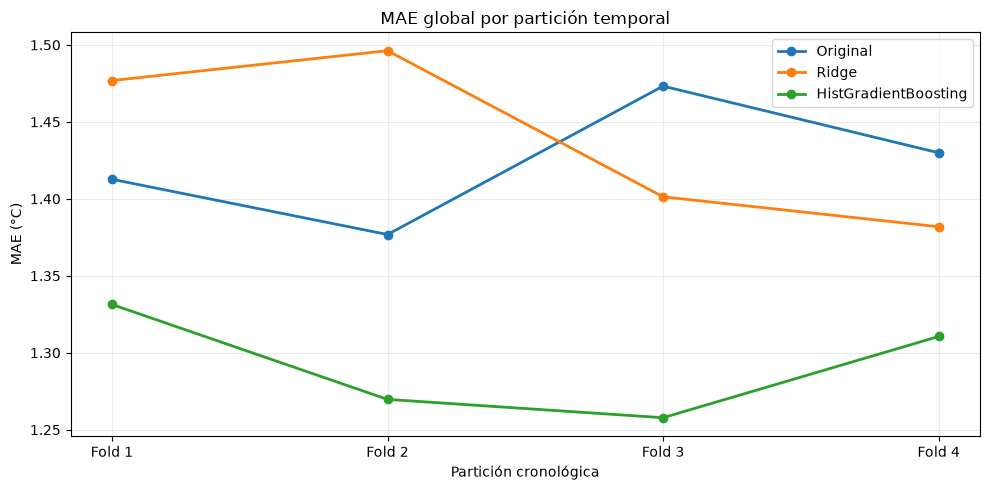


CONTROL FINAL:
Cuatro folds históricos analizados.
513506 registros de validación cruzada.
HGB mejoró el MAE en los cuatro folds.
HGB superó a Ridge en ambos horizontes.
Resultados ponderados verificados.
No se reentrenaron modelos.
Prueba final de noviembre intacta.


In [3]:

# ==========================================
# 07 - CELDA 3
# ESTABILIDAD TEMPORAL DE RIDGE Y HGB
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. RECUPERAR VALIDACIÓN CRUZADA
# ------------------------------------------

df_folds_07 = datos["cv_folds"].copy()

assert len(df_folds_07) == 12

# Identificar resultados globales
df_global_folds_07 = (
    df_folds_07.loc[
        df_folds_07["horizonte_h"]
        .astype(str).eq("Global")
    ]
    .sort_values("fold")
    .reset_index(drop=True)
)

assert len(df_global_folds_07) == 4
assert df_global_folds_07["fold"].tolist() == [1, 2, 3, 4]

# ------------------------------------------
# 2. COMPARAR RENDIMIENTO POR FOLD
# ------------------------------------------

print("RENDIMIENTO GLOBAL POR FOLD:")

display(
    df_global_folds_07[
        [
            "fold",
            "registros",
            "MAE_original_c",
            "MAE_ridge_c",
            "MAE_hgb_c",
            "mejora_ridge_pct",
            "mejora_hgb_pct"
        ]
    ].round(4)
)

# ------------------------------------------
# 3. ESTABILIDAD POR HORIZONTE
# ------------------------------------------

df_horizontes_folds_07 = df_folds_07.loc[
    df_folds_07["horizonte_h"]
    .astype(str).isin(["12", "24"])
].copy()

resumen_estabilidad_07 = []

for horizonte in [12, 24]:

    seleccion = df_horizontes_folds_07.loc[
        df_horizontes_folds_07["horizonte_h"]
        .astype(str).eq(str(horizonte))
    ]

    resumen_estabilidad_07.append({
        "horizonte_h": horizonte,
        "folds": len(seleccion),
        "ridge_mejora": int(
            (seleccion["mejora_ridge_pct"] > 0).sum()
        ),
        "hgb_mejora": int(
            (seleccion["mejora_hgb_pct"] > 0).sum()
        ),
        "hgb_supera_ridge": int(
            (
                seleccion["MAE_hgb_c"]
                < seleccion["MAE_ridge_c"]
            ).sum()
        ),
        "mejora_hgb_min_pct": (
            seleccion["mejora_hgb_pct"].min()
        ),
        "mejora_hgb_max_pct": (
            seleccion["mejora_hgb_pct"].max()
        )
    })

df_estabilidad_07 = pd.DataFrame(
    resumen_estabilidad_07
)

print("\nESTABILIDAD POR HORIZONTE:")

display(df_estabilidad_07.round(4))

# ------------------------------------------
# 4. VERIFICACIÓN CONTRA RESULTADO CONSOLIDADO
# ------------------------------------------

registros_total = (
    df_global_folds_07["registros"].sum()
)

assert registros_total == 513506

# El MAE consolidado debe coincidir con
# el promedio ponderado por registros.
mae_ponderado_hgb = np.average(
    df_global_folds_07["MAE_hgb_c"],
    weights=df_global_folds_07["registros"]
)

mae_ponderado_ridge = np.average(
    df_global_folds_07["MAE_ridge_c"],
    weights=df_global_folds_07["registros"]
)

fila_cv_global = df_07_cv.loc[
    df_07_cv["horizonte_h"]
    .astype(str).eq("Global")
].iloc[0]

assert np.isclose(
    mae_ponderado_hgb,
    fila_cv_global["MAE_hgb_c"],
    atol=1e-6
)

assert np.isclose(
    mae_ponderado_ridge,
    fila_cv_global["MAE_ridge_c"],
    atol=1e-6
)

# ------------------------------------------
# 5. GRÁFICO DE MAE POR FOLD
# ------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

series = [
    ("MAE_original_c", "Original"),
    ("MAE_ridge_c", "Ridge"),
    ("MAE_hgb_c", "HistGradientBoosting")
]

for columna, nombre in series:

    ax.plot(
        df_global_folds_07["fold"],
        df_global_folds_07[columna],
        marker="o",
        linewidth=2,
        label=nombre
    )

ax.set_xticks([1, 2, 3, 4])

ax.set_xticklabels([
    "Fold 1",
    "Fold 2",
    "Fold 3",
    "Fold 4"
])

ax.set_title(
    "MAE global por partición temporal"
)

ax.set_xlabel("Partición cronológica")
ax.set_ylabel("MAE (°C)")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

# ------------------------------------------
# 6. EXPORTAR RESULTADOS
# ------------------------------------------

ruta_resumen_estabilidad = (
    carpeta_evaluacion
    / "03_resumen_robustez_temporal.csv"
)

ruta_grafico_estabilidad = (
    carpeta_evaluacion
    / "04_mae_por_fold_temporal.png"
)

df_estabilidad_07.to_csv(
    ruta_resumen_estabilidad,
    index=False,
    encoding="utf-8-sig"
)

fig.savefig(
    ruta_grafico_estabilidad,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------
# 7. CONTROLES FINALES
# ------------------------------------------

assert (
    df_estabilidad_07["folds"] == 4
).all()

assert (
    df_estabilidad_07["hgb_mejora"] == 4
).all()

assert (
    df_estabilidad_07["hgb_supera_ridge"] == 4
).all()

assert ruta_resumen_estabilidad.is_file()
assert ruta_grafico_estabilidad.is_file()

print("\nCONTROL FINAL:")
print("Cuatro folds históricos analizados.")
print("513506 registros de validación cruzada.")
print("HGB mejoró el MAE en los cuatro folds.")
print("HGB superó a Ridge en ambos horizontes.")
print("Resultados ponderados verificados.")
print("No se reentrenaron modelos.")
print("Prueba final de noviembre intacta.")


#### Robustez temporal completada
Comparación temporal verificada

Registros de validación cruzada
513.506

Mejora global HGB
9,35 %



Fold	Mejora Ridge	Mejora HGB
1	−4,54 %	+5,76 %
2	−8,67 %	+7,78 %
3	+4,88 %	+14,62 %
4	+3,36 %	+8,35 %

La conclusión es clara: HGB superó tanto al pronóstico original como a Ridge en los cuatro folds, mientras que Ridge empeoró en los primeros dos.

El gráfico es adecuado para la entrega. Los cuatro folds corresponden a ventanas cronológicas distintas, por lo que debemos describirlo como una comparación entre períodos de validación, no como la evolución de un mismo modelo fijo.

#### Evaluación final independiente
En esta última sección cuantitativa vamos a presentar los resultados definitivos del modelo congelado sobre los días 2 al 9 de noviembre de 2026.
Horizonte	MAE original	MAE corregido	Mejora
12 horas	1,4620 °C	1,3051 °C	10,73 %
24 horas	1,5194 °C	1,3635 °C	10,26 %
Global	1,4907 °C	1,3343 °C	10,49 %

Esta es nuestra evaluación final. No ajustaremos ningún modelo utilizando sus resultados

CONTROL DE COHERENCIA:
Métricas diarias y globales coincidentes.

PRUEBA FINAL POR HORIZONTE:


,horizonte_h,registros,MAE_original_c,MAE_corregido_c,RMSE_original_c,RMSE_corregido_c,sesgo_original_c,sesgo_corregido_c,mejora_MAE_pct
0,12,70401,1.4620,1.3051,1.8458,1.6669,0.3144,0.1291,10.7273
1,24,70421,1.5194,1.3635,1.9136,1.7347,0.3628,0.1792,10.2572



PRUEBA FINAL GLOBAL:


,registros,MAE_original_c,MAE_corregido_c,RMSE_original_c,RMSE_corregido_c,sesgo_original_c,sesgo_corregido_c,mejora_MAE_pct
0,140822,1.4907,1.3343,1.88,1.7012,0.3386,0.1541,10.4877



CONSISTENCIA DIARIA:


,horizonte_h,dias_evaluados,dias_con_mejora,mejora_minima_pct,mejora_maxima_pct,registros_sin_lag
0,12,8,8,6.6409,14.9076,63
1,24,8,8,3.5838,16.5142,97


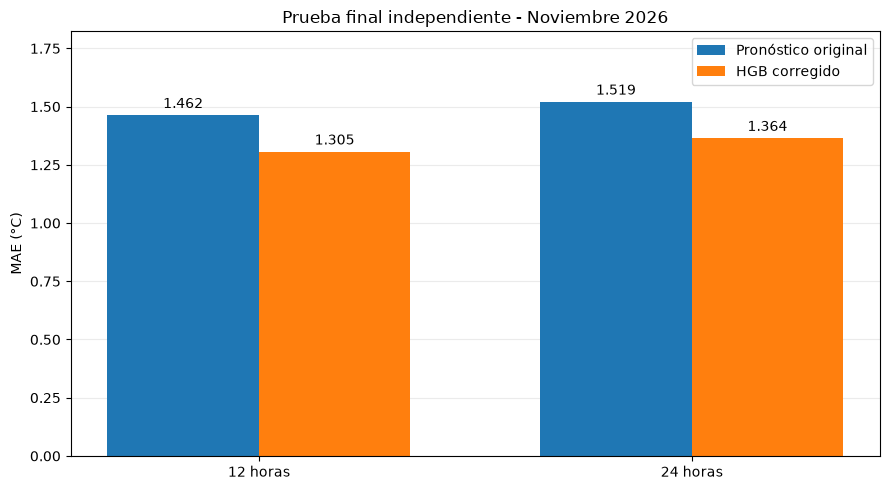

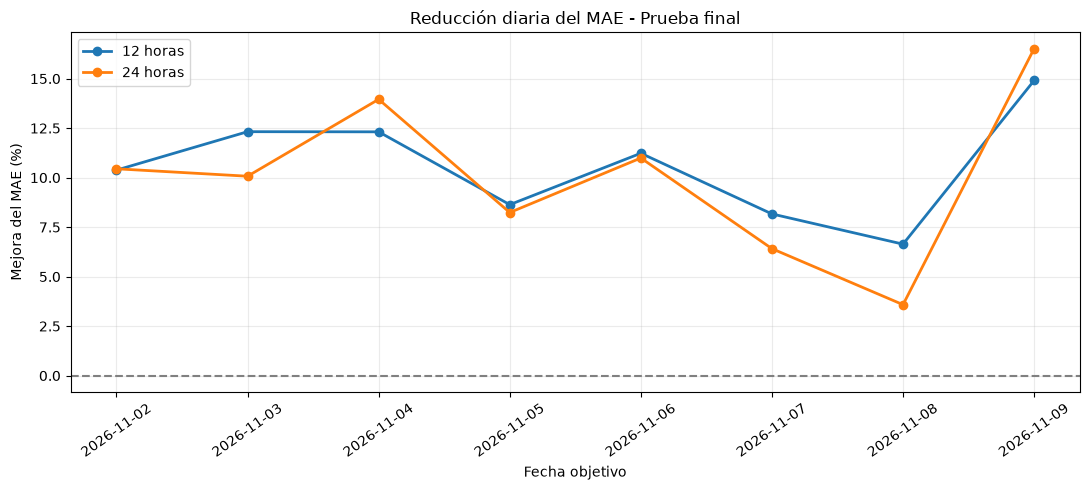


ARCHIVOS GENERADOS:
01_comparacion_seis_modelos.csv
02_comparacion_seis_modelos.png
03_resumen_robustez_temporal.csv
04_mae_por_fold_temporal.png
05_metricas_test_por_horizonte.csv
06_metricas_test_global.csv
07_metricas_diarias_test.csv
08_mae_prueba_final.png
09_mejora_diaria_test.png

CONTROL FINAL:
140822 registros del test final verificados.
Ocho días y dos horizontes comprobados.
16 combinaciones con mejora positiva.
160 registros sin lag histórico.
Métricas diarias reconciliadas.
No se reentrenaron modelos.
No se modificó el modelo final.
Resultados de evaluación exportados.


In [4]:

# ==========================================
# 07 - CELDA 4
# EVALUACIÓN FINAL INDEPENDIENTE
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. RECUPERAR RESULTADOS YA CALCULADOS
# ------------------------------------------

df_test_horizontes_07 = (
    datos["test_horizontes"].copy()
)

df_test_global_07 = (
    datos["test_global"].copy()
)

ruta_diarios = (
    raiz / "resultados_ml"
    / "03_metricas_diarias.csv"
)

assert ruta_diarios.is_file()

df_test_diario_07 = pd.read_csv(
    ruta_diarios
)

df_test_diario_07["fecha"] = pd.to_datetime(
    df_test_diario_07["fecha"]
)

# ------------------------------------------
# 2. VERIFICAR PERÍODO Y CANTIDADES
# ------------------------------------------

fechas_esperadas = pd.date_range(
    "2026-11-02",
    "2026-11-09",
    freq="D"
)

assert sorted(
    df_test_diario_07["fecha"].unique()
) == list(fechas_esperadas)

assert len(df_test_diario_07) == 16
assert len(df_test_horizontes_07) == 2
assert len(df_test_global_07) == 1

assert (
    df_test_diario_07["registros"].sum()
    == 140822
)

assert (
    df_test_global_07["registros"].iloc[0]
    == 140822
)

assert (
    df_test_horizontes_07["registros"].sum()
    == 140822
)

# ------------------------------------------
# 3. RECONCILIAR MÉTRICAS DIARIAS
# ------------------------------------------

# El promedio de los MAE diarios ponderado por
# registros debe reproducir el MAE por horizonte.

for horizonte in [12, 24]:

    diarios = df_test_diario_07.loc[
        df_test_diario_07["horizonte_h"]
        == horizonte
    ]

    resumen = df_test_horizontes_07.loc[
        df_test_horizontes_07["horizonte_h"]
        == horizonte
    ].iloc[0]

    assert len(diarios) == 8

    assert (
        diarios["registros"].sum()
        == resumen["registros"]
    )

    for origen, destino in [
        ("MAE_original", "MAE_original_c"),
        ("MAE_corregido", "MAE_corregido_c")
    ]:

        promedio = np.average(
            diarios[origen],
            weights=diarios["registros"]
        )

        assert np.isclose(
            promedio,
            resumen[destino],
            atol=5e-4
        )

# Verificación global de métricas
for origen, destino in [
    ("MAE_original", "MAE_original_c"),
    ("MAE_corregido", "MAE_corregido_c")
]:

    promedio_global = np.average(
        df_test_diario_07[origen],
        weights=df_test_diario_07["registros"]
    )

    assert np.isclose(
        promedio_global,
        df_test_global_07[destino].iloc[0],
        atol=5e-4
    )

print("CONTROL DE COHERENCIA:")
print("Métricas diarias y globales coincidentes.")

# ------------------------------------------
# 4. RESULTADOS POR HORIZONTE
# ------------------------------------------

print("\nPRUEBA FINAL POR HORIZONTE:")

display(
    df_test_horizontes_07.round(4)
)

print("\nPRUEBA FINAL GLOBAL:")

display(
    df_test_global_07.round(4)
)

# ------------------------------------------
# 5. CONSISTENCIA DE LA MEJORA DIARIA
# ------------------------------------------

df_test_diario_07["mejora_verificada_pct"] = (
    100 * (
        1
        - df_test_diario_07["MAE_corregido"]
        / df_test_diario_07["MAE_original"]
    )
)

assert np.isfinite(
    df_test_diario_07["mejora_verificada_pct"]
).all()

assert (
    df_test_diario_07["mejora_verificada_pct"] > 0
).all()

resumen_diario = (
    df_test_diario_07
    .groupby("horizonte_h")
    .agg(
        dias_evaluados=("fecha", "nunique"),
        dias_con_mejora=(
            "mejora_verificada_pct",
            lambda s: int((s > 0).sum())
        ),
        mejora_minima_pct=(
            "mejora_verificada_pct", "min"
        ),
        mejora_maxima_pct=(
            "mejora_verificada_pct", "max"
        ),
        registros_sin_lag=("sin_lag", "sum")
    )
    .reset_index()
)

print("\nCONSISTENCIA DIARIA:")

display(resumen_diario.round(4))

assert (
    resumen_diario["dias_con_mejora"] == 8
).all()

assert resumen_diario["registros_sin_lag"].sum() == 160

# ------------------------------------------
# 6. GRÁFICO: MAE ORIGINAL VS CORREGIDO
# ------------------------------------------

tabla = df_test_horizontes_07.sort_values(
    "horizonte_h"
)

x = np.arange(len(tabla))
ancho = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

b1 = ax.bar(
    x - ancho / 2,
    tabla["MAE_original_c"],
    ancho,
    label="Pronóstico original"
)

b2 = ax.bar(
    x + ancho / 2,
    tabla["MAE_corregido_c"],
    ancho,
    label="HGB corregido"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{h} horas" for h in tabla["horizonte_h"]]
)

ax.bar_label(b1, fmt="%.3f", padding=3)
ax.bar_label(b2, fmt="%.3f", padding=3)

ax.set_ylabel("MAE (°C)")
ax.set_title(
    "Prueba final independiente - Noviembre 2026"
)

ax.set_ylim(
    0,
    tabla["MAE_original_c"].max() * 1.2
)

ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()

# ------------------------------------------
# 7. GRÁFICO: MEJORA DIARIA
# ------------------------------------------

tabla_diaria = df_test_diario_07.pivot(
    index="fecha",
    columns="horizonte_h",
    values="mejora_verificada_pct"
).sort_index()

fig_diario, ax_diario = plt.subplots(
    figsize=(11, 5)
)

for horizonte in [12, 24]:

    ax_diario.plot(
        tabla_diaria.index,
        tabla_diaria[horizonte],
        marker="o",
        linewidth=2,
        label=f"{horizonte} horas"
    )

ax_diario.axhline(
    0,
    color="gray",
    linestyle="--"
)

ax_diario.set_title(
    "Reducción diaria del MAE - Prueba final"
)

ax_diario.set_xlabel("Fecha objetivo")
ax_diario.set_ylabel("Mejora del MAE (%)")
ax_diario.tick_params(axis="x", rotation=35)
ax_diario.grid(alpha=0.25)
ax_diario.legend()

fig_diario.tight_layout()

# ------------------------------------------
# 8. EXPORTAR RESULTADOS FINALES
# ------------------------------------------

carpeta_evaluacion.mkdir(
    parents=True,
    exist_ok=True
)

exportaciones = {
    "05_metricas_test_por_horizonte.csv":
        df_test_horizontes_07,
    "06_metricas_test_global.csv":
        df_test_global_07,
    "07_metricas_diarias_test.csv":
        df_test_diario_07
}

for nombre, tabla_exportar in exportaciones.items():

    tabla_exportar.to_csv(
        carpeta_evaluacion / nombre,
        index=False,
        encoding="utf-8-sig"
    )

fig.savefig(
    carpeta_evaluacion
    / "08_mae_prueba_final.png",
    dpi=180,
    bbox_inches="tight"
)

fig_diario.savefig(
    carpeta_evaluacion
    / "09_mejora_diaria_test.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

plt.show()
plt.close(fig_diario)

# ------------------------------------------
# 9. CONTROL FINAL
# ------------------------------------------

print("\nARCHIVOS GENERADOS:")

for archivo in sorted(
    carpeta_evaluacion.iterdir()
):
    if archivo.is_file():
        print(archivo.name)

print("\nCONTROL FINAL:")
print("140822 registros del test final verificados.")
print("Ocho días y dos horizontes comprobados.")
print("16 combinaciones con mejora positiva.")
print("160 registros sin lag histórico.")
print("Métricas diarias reconciliadas.")
print("No se reentrenaron modelos.")
print("No se modificó el modelo final.")
print("Resultados de evaluación exportados.")


#### Evaluación comparativa completada

Reducción global del MAE en la prueba final
10,49 %
Pronósticos
140.822

MAE original
1,4907 °C

MAE corregido
1,3343 °C



La comprobación diaria también resultó satisfactoria:
Indicador	12 horas	24 horas
Días evaluados	8	8
Días con mejora del MAE	8	8
Mejora mínima diaria	6,64 %	3,58 %
Mejora máxima diaria	14,91 %	16,51 %
Registros sin lag disponible	63	97

Conclusión: HGB consiguió mejorar el error absoluto medio en los dos horizontes y en todos los días del período evaluado. El resultado es sólido para este conjunto de prueba, aunque no garantiza el mismo desempeño en otros períodos meteorológicos.

También redujo el sesgo global de +0,3386 °C a +0,1541 °C, sin eliminarlo completamente.


## Conclusiones de la evaluación comparativa

Se compararon seis alternativas de corrección del error
meteorológico sobre un conjunto común de validación
histórica de 173.583 registros.

El modelo HistGradientBoosting con errores históricos
obtuvo el menor MAE (1,4361 °C), con una mejora del
8,18 % respecto del pronóstico original.

La validación cruzada temporal, realizada con cuatro
particiones y 513.506 predicciones fuera de entrenamiento,
mostró una reducción global del MAE del 9,35 % para HGB.
El modelo mejoró el pronóstico original en todos los folds
y superó a Ridge en ambos horizontes.

El análisis de interpretabilidad identificó asociaciones
predictivas relevantes con el ciclo solar, la velocidad
del viento, la precipitación y los errores históricos.

En la prueba final independiente, correspondiente al
2–9 de noviembre de 2026, el modelo HGB congelado
redujo el MAE global de 1,4907 °C a 1,3343 °C,
equivalente a una mejora del 10,49 %.

La mejora se observó en los ocho días y en ambos
horizontes de pronóstico.

### Limitaciones

- La prueba final abarca solamente ocho días.
- Los registros de las estaciones no son independientes.
- La disponibilidad de las observaciones fue estimada
  mediante tiempos de recolección y un margen de dos horas.
- La evaluación es retrospectiva y secuencial.
- La validación cruzada retrospectiva utiliza
  hiperparámetros seleccionados anteriormente.
- La prueba final se realizó con HGB; no constituye
  una comparación directa con Ridge sobre noviembre.

### Conclusión general

Los resultados respaldan la utilidad de HistGradientBoosting
como modelo de corrección de temperatura para los horizontes
de 12 y 24 horas estudiados.

Se requieren evaluaciones adicionales para comprobar su
generalización a otros períodos y condiciones meteorológicas.
